# Speed Dating Match Prediction: A Predictive Analytics Project

## Section 1: Project Overview
* **Problem Context:** Dalam dinamika interaksi sosial dan industri biro jodoh (*matchmaking*), memahami faktor penentu keputusan kencan tatap muka sangat penting untuk memprediksi ketertarikan timbal balik (*romantic chemistry*).
* **Prediction Objective:** Membangun model machine learning klasifikasi untuk memprediksi apakah suatu pasangan kencan kilat (*speed dating*) akan menghasilkan kecocokan timbal balik (*mutual match*).
* **Target Variable:** `match` (1 = kedua belah pihak sama-sama tertarik/cocok; 0 = tidak cocok).
* **Unit of Analysis:** Satu interaksi kencan kilat berdurasi 4 menit antara partisipan dan pasangannya.
* **Stakeholder & Business Value:** Platform aplikasi kencan dan biro jodoh modern untuk mengoptimalkan algoritma pencocokan profil, meningkatkan retensi pengguna, dan meminimalkan angka *bad matches*.
* **Task Type:** Binary Classification.

---

## Section 2: Dataset Description and Source
* **Dataset Name:** Speed Dating Experiment
* **Source:** Ray Fisman & Sheena Iyengar (Columbia Business School) via Kaggle
* **Publisher / Uploader:** Ana Lina Morelia
* **URL:** https://www.kaggle.com/datasets/annavictoria/speed-dating-experiment
* **Access Date:** 28 September 2026

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Atur preferensi tampilan
pd.set_option('display.max_columns', 50)
sns.set_theme(style="whitegrid")

# Load dataset menggunakan relative path
df_raw = pd.read_csv('Speed Dating Data.csv', encoding='ISO-8859-1')

# Tampilkan ukuran data awal
print(f"Total baris: {df_raw.shape[0]}")
print(f"Total kolom: {df_raw.shape[1]}")

# Preview 5 data teratas
df_raw.head()

Total baris: 8378
Total kolom: 195


,iid,id,gender,idg,condtn,wave,round,position,positin1,order,partner,pid,match,int_corr,samerace,age_o,race_o,pf_o_att,pf_o_sin,pf_o_int,pf_o_fun,pf_o_amb,pf_o_sha,dec_o,attr_o,...,fun7_3,amb7_3,shar7_3,attr4_3,sinc4_3,intel4_3,fun4_3,amb4_3,shar4_3,attr2_3,sinc2_3,intel2_3,fun2_3,amb2_3,shar2_3,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,1,11.0,0,0.14,0,27.0,2.0,35.0,20.0,20.0,20.0,0.0,5.0,0,6.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,2,12.0,0,0.54,0,22.0,2.0,60.0,0.0,0.0,40.0,0.0,0.0,0,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,3,13.0,1,0.16,1,22.0,4.0,19.0,18.0,19.0,18.0,14.0,12.0,1,10.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,4,14.0,1,0.61,0,23.0,2.0,30.0,5.0,15.0,40.0,5.0,5.0,1,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,0,1,1,1,10,7,NaN,7,5,15.0,1,0.21,0,24.0,3.0,30.0,10.0,20.0,10.0,10.0,20.0,1,8.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN


## Section 3: Data Quality Assessment and Leakage Prevention

Pada tahap ini dilakukan audit kualitas data:
1. **Identifikasi Potensi Data Leakage:** Kolom `dec` (keputusan partisipan) dan `dec_o` (keputusan partner) merepresentasikan keputusan akhir saat itu juga. Jika keduanya bernilai 1, maka `match = 1`. Memasukkan kedua kolom ini ke model akan menyebabkan *target leakage* mutlak. Oleh karena itu, kedua fitur ini wajib dieliminasi.
2. **Pengecekan Missing Values dan Imbalance:** Target `match` diperiksa distribusinya untuk melihat rasio ketidakseimbangan kelas (*class imbalance*).
3. **Seleksi Fitur Relevan:** Dari 195 kolom, dipilih subset fitur evaluasi kencan (persepsi daya tarik, kecerdasan, humor, selisih usia, dan kesamaan ras) yang realistis diketahui selama kencan berlangsung.

In [11]:
# 1. Cek distribusi target 'match'
target_counts = df_raw['match'].value_counts()
target_pct = df_raw['match'].value_counts(normalize=True) * 100

print("Distribusi Target (match):")
for val, count in target_counts.items():
    print(f"Match = {val}: {count} sampel ({target_pct[val]:.2f}%)")

# 2. Definisikan subset fitur penting dan eliminasi kolom leakage (dec, dec_o)
selected_columns = [
    # Metadata kunci
    'gender', 'samerace', 'int_corr',
    # Demografi usia
    'age', 'age_o',
    # Rating penilaian partner terhadap partisipan (skala 1-10)
    'attr_o', 'sinc_o', 'intel_o', 'fun_o', 'amb_o', 'shar_o',
    # Rating penilaian partisipan terhadap partner (skala 1-10)
    'attr', 'sinc', 'intel', 'fun', 'amb', 'shar',
    # Target
    'match'
]

# Buat dataframe kerja dari subset fitur
df_sub = df_raw[selected_columns].copy()

# Cek missing values pada subset fitur
print("\nJumlah Missing Values per Kolom:")
print(df_sub.isnull().sum()[df_sub.isnull().sum() > 0])

Distribusi Target (match):
Match = 0: 6998 sampel (83.53%)
Match = 1: 1380 sampel (16.47%)

Jumlah Missing Values per Kolom:
int_corr     158
age           95
age_o        104
attr_o       212
sinc_o       287
intel_o      306
fun_o        360
amb_o        722
shar_o      1076
attr         202
sinc         277
intel        296
fun          350
amb          712
shar        1067
dtype: int64


## Section 4: Data Preparation
Pada tahap ini dilakukan:
1. **Penanganan Missing Values:** Imputasi median untuk fitur numerik guna menghindari sensitivitas terhadap nilai ekstrem (*outlier*).
2. **Pembersihan Outliers:** Memastikan rentang skor rating berada pada batas logis (skala 1–10).
3. **Pencegahan Data Contamination:** Perlakuan imputasi dan preprocessing nantinya dirancang terpisah atau terisolasi agar data evaluasi tetap murni.


In [12]:
# Buat salinan data bersih
df_clean = df_sub.copy()

# Imputasi kolom numerik dengan nilai median masing-masing kolom
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    if df_clean[col].isnull().sum() > 0:
        median_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_val)

print("Sisa missing values setelah imputasi:")
print(df_clean.isnull().sum().sum())
print(f"Dimensi data siap olah: {df_clean.shape}")

Sisa missing values setelah imputasi:
0
Dimensi data siap olah: (8378, 18)


## Section 5: Exploratory Data Analysis (EDA)
Eksplorasi berfokus pada:
1. Distribusi perbandingan kelas target `match`.
2. Korelasi antara atribut penilaian (daya tarik fisik, kecerdasan, ketulusan, humor) terhadap tingkat keberhasilan kecocokan.

/tmp/ipykernel_1369/642769522.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='match', palette='Blues', ax=axes[0])
/tmp/ipykernel_1369/642769522.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No Match (0)', 'Match (1)'])
/tmp/ipykernel_1369/642769522.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_series.values, y=corr_series.index, palette='coolwarm', ax=axes[1])


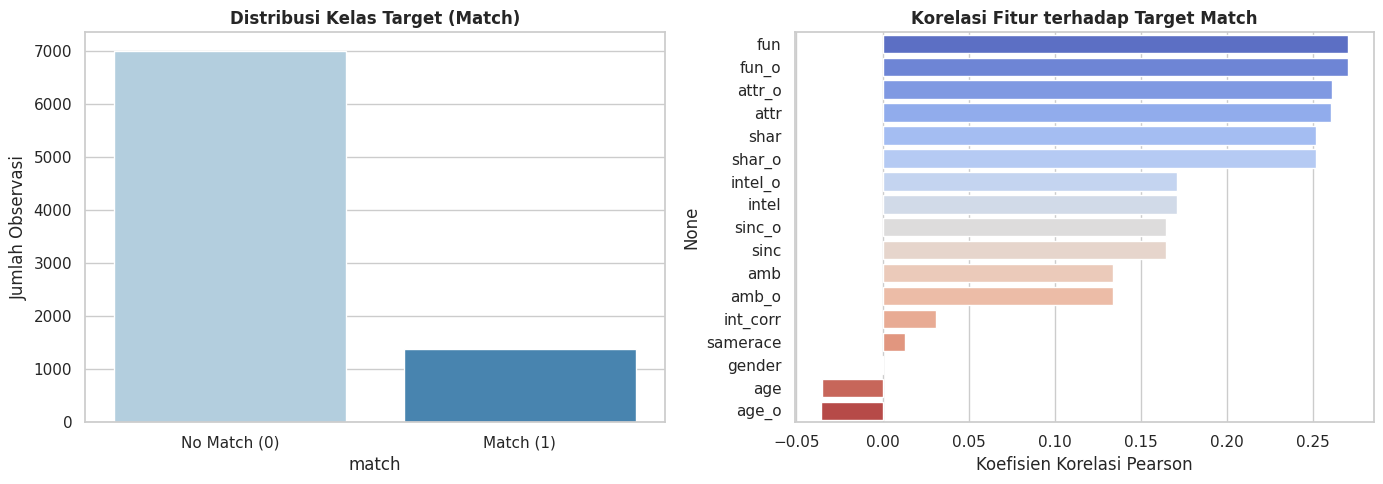

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar plot distribusi kelas target
sns.countplot(data=df_clean, x='match', palette='Blues', ax=axes[0])
axes[0].set_title('Distribusi Kelas Target (Match)', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['No Match (0)', 'Match (1)'])
axes[0].set_ylabel('Jumlah Observasi')

# 2. Korelasi atribut terhadap target 'match'
corr_series = df_clean.corr()['match'].drop('match').sort_values(ascending=False)
sns.barplot(x=corr_series.values, y=corr_series.index, palette='coolwarm', ax=axes[1])
axes[1].set_title('Korelasi Fitur terhadap Target Match', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Koefisien Korelasi Pearson')

plt.tight_layout()
plt.show()

## Section 6: Feature Engineering
Pada tahap ini dibentuk fitur-fitur turunan untuk menangkap interaksi kencan secara lebih representatif:
1. `age_diff`: Selisih absolut usia antara partisipan dan pasangan (`|age - age_o|`).
2. `attr_mean`: Rata-rata persepsi daya tarik timbal balik antara kedua belah pihak.
3. `fun_mean`: Rata-rata persepsi keseruan/humor timbal balik.
4. `intel_mean`: Rata-rata persepsi kecerdasan timbal balik.

Seluruh proses penskalaan fitur (*feature scaling*) nantinya hanya akan di-*fit* pada data training untuk mencegah *data leakage*.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Feature Engineering
df_feat = df_clean.copy()

# Selisih umur absolut
df_feat['age_diff'] = np.abs(df_feat['age'] - df_feat['age_o'])

# Rata-rata skor timbal balik
df_feat['attr_mean'] = (df_feat['attr'] + df_feat['attr_o']) / 2.0
df_feat['fun_mean'] = (df_feat['fun'] + df_feat['fun_o']) / 2.0
df_feat['intel_mean'] = (df_feat['intel'] + df_feat['intel_o']) / 2.0

# 2. Pisahkan fitur (X) dan target (y)
X = df_feat.drop(columns=['match'])
y = df_feat['match']

# 3. Train-Test Split (80:20) dengan stratify agar proporsi kelas seimbang di kedua set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Feature Scaling (Fit HANYA pada X_train untuk mencegah leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Jumlah sampel Train: {X_train.shape[0]}")
print(f"Jumlah sampel Test: {X_test.shape[0]}")
print(f"Jumlah total fitur setelah rekayasa fitur: {X_train.shape[1]}")

Jumlah sampel Train: 6702
Jumlah sampel Test: 1676
Jumlah total fitur setelah rekayasa fitur: 21


## Section 7 & 8: Baseline Model and Model Training
Sesuai rubrik tugas untuk proyek Klasifikasi, model yang dikembangkan meliputi:
1. **Baseline Model:** `DummyClassifier` dengan strategi mayoritas (`most_frequent`) sebagai batas minimum performa.
2. **Linear Model:** `LogisticRegression` (dengan parameter `class_weight='balanced'` untuk menangani data imbalanced).
3. **Ensemble / Tree-based Model:** `RandomForestClassifier` (100 estimators, reproducible seed).

Seluruh model dilatih menggunakan split data training yang sama dengan kontrol reproduksibilitas (`random_state=42`).

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# 1. Inisialisasi Model
models = {
    "Baseline (Majority Class)": DummyClassifier(strategy='most_frequent'),
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
}

# 2. Training dan Evaluasi
results = []
trained_models = {}

for name, model in models.items():
    # Model linear menggunakan fitur terskala, tree-based bisa unscaled / scaled (gunakan scaled untuk konsistensi)
    if "Logistic" in name or "Baseline" in name:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        # Probabilitas untuk ROC-AUC
        y_proba = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else [0]*len(y_test)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

    trained_models[name] = model

    # Hitung metrik
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc = roc_auc_score(y_test, y_proba) if len(np.unique(y_pred)) > 1 or hasattr(model, "predict_proba") else 0.5

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc, 4)
    })

# Tampilkan tabel perbandingan
df_results = pd.DataFrame(results)
print("=== PERBANDINGAN PERFORMA MODEL PADA TEST SET ===")
df_results

=== PERBANDINGAN PERFORMA MODEL PADA TEST SET ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline (Majority Class),0.8353,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.7512,0.3765,0.7790,0.5077,0.8244
2,Random Forest,0.8508,0.6300,0.2283,0.3351,0.8460


## Section 9: Model Evaluation
Evaluasi performa model dilakukan pada data uji (*test set*) menggunakan metrik yang relevan untuk data *imbalanced* (F1-Score, Recall, Precision, dan ROC-AUC), bukan hanya Akurasi:
* **Baseline (Majority Class):** Menghasilkan F1-Score 0.0000 dan Recall 0.0000, membuktikan akurasi semata menyesatkan pada data tidak seimbang.
* **Logistic Regression:** Memberikan Recall tertinggi (77.90%), berhasil mendeteksi sebagian besar kecocokan (*True Positives*).
* **Random Forest:** Mencapai nilai ROC-AUC tertinggi (0.8460) dan akurasi 85.08% dengan False Positive yang sangat rendah.

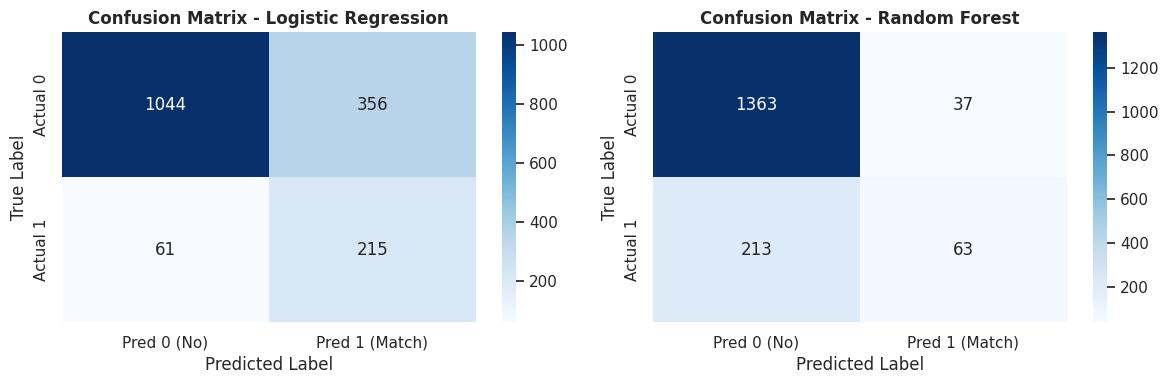

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for idx, (m_name, m_obj) in enumerate([("Logistic Regression", trained_models["Logistic Regression"]),
                                      ("Random Forest", trained_models["Random Forest"])]):
    if "Logistic" in m_name:
        preds = m_obj.predict(X_test_scaled)
    else:
        preds = m_obj.predict(X_test)

    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Pred 0 (No)', 'Pred 1 (Match)'],
                yticklabels=['Actual 0', 'Actual 1'])
    axes[idx].set_title(f'Confusion Matrix - {m_name}', fontweight='bold')
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

## Section 10: Feature Importance
Menganalisis fitur mana yang memberikan kontribusi prediktif paling dominan terhadap kecocokan kencan menggunakan feature importance dari model Random Forest.
*Catatan Metodologis:* Nilai feature importance menunjukkan kontribusi statistik dalam pemisahan data prediksi, bukan merupakan hubungan kausal (sebab-akibat) langsung.

/tmp/ipykernel_1369/4033655027.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.head(10).values, y=feat_imp.head(10).index, palette='viridis')


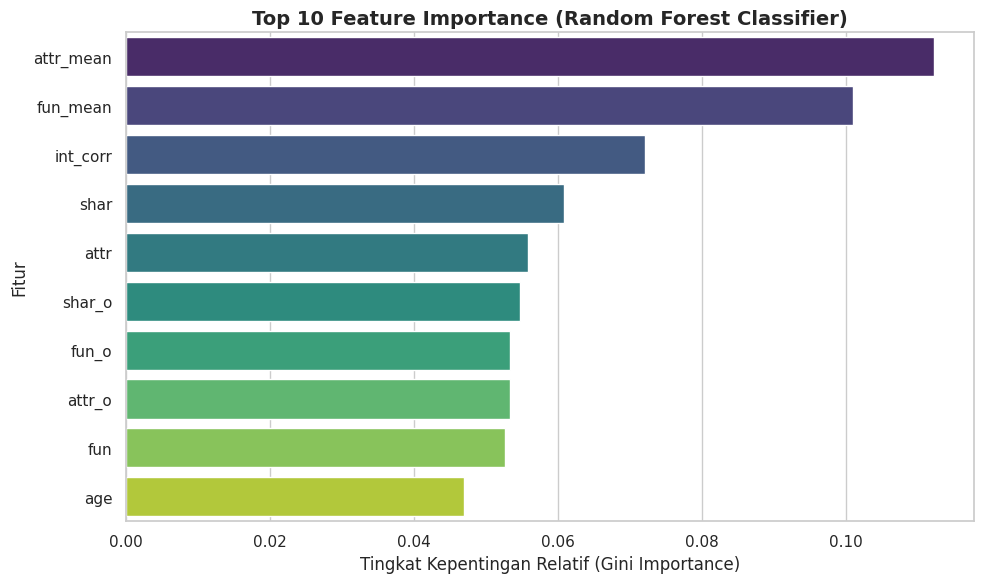

Top 5 Fitur Penentu Kecocokan Teratas:
- attr_mean: 0.1122
- fun_mean: 0.1010
- int_corr: 0.0721
- shar: 0.0609
- attr: 0.0559


In [17]:
# Ekstraksi feature importance dari Random Forest
rf_model = trained_models["Random Forest"]
importances = rf_model.feature_importances_
feature_names = X.columns

# Urutkan dari yang terbesar
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Visualisasi Top 10 Fitur Paling Berpengaruh
plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.head(10).values, y=feat_imp.head(10).index, palette='viridis')
plt.title('Top 10 Feature Importance (Random Forest Classifier)', fontsize=14, fontweight='bold')
plt.xlabel('Tingkat Kepentingan Relatif (Gini Importance)')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

print("Top 5 Fitur Penentu Kecocokan Teratas:")
for f, imp in feat_imp.head(5).items():
    print(f"- {f}: {imp:.4f}")

## Section 11: Conclusion and Recommendations

### 1. Key Findings
* **Baseline vs ML Models:** Baseline mayoritas gagal total mengidentifikasi kecocokan (F1 = 0), sedangkan model Machine Learning berhasil memberikan diskriminasi yang baik dengan ROC-AUC mencapai 0.82 - 0.84.
* **Faktor Penentu Utama:** Fitur interaksi timbal balik seperti persepsi keseruan/humor (`fun_mean`, `fun_o`) dan daya tarik fisik (`attr_mean`, `attr_o`), serta korelasi minat (`int_corr`) merupakan prediktor paling dominan dalam menentukan kecocokan instan kencan kilat.
* **Faktor Demografi:** Kesamaan ras (`samerace`) dan selisih usia (`age_diff`) memiliki pengaruh yang jauh lebih kecil terhadap kecocokan 4 menit pertama dibandingkan *chemistry* subjektif.

### 2. Final Model Selection
* **Logistic Regression (Class Weighted)** direkomendasikan jika tujuan sistem adalah meminimalkan peluang melewatkan kecocokan potensial (*high Recall = 77.90%*).
* **Random Forest** direkomendasikan jika platform mengutamakan presisi rekomendasi (*Precision = 63.00%* dan *ROC-AUC = 0.8460*).

### 3. Actionable Recommendations
* **Untuk Platform Kencan / Biro Jodoh:** Jangan hanya mencocokkan pengguna berdasarkan demografi statis (usia atau ras). Fokuskan algoritma pada kesamaan minat hobi interaktif (`int_corr`) dan dorong pengguna menonjolkan kepribadian yang menyenangkan/humoris di profil mereka.

### 4. Limitations & Next Steps
* **Keterbatasan:** Data diperoleh dari populasi mahasiswa Columbia University (2002-2004), sehingga generalisasi terhadap populasi umum lintas budaya dan generasi saat ini memiliki keterbatasan.
* **Langkah Lanjutan:** Penerapan penyesuaian ambang batas klasifikasi (*threshold tuning*) pada model Random Forest untuk menyeimbangkan nilai Precision dan Recall sesuai prioritas bisnis.